# Cameron Peak and East Troublesome Fire Burn Severity
## MTBS Comparison

- **Objective:**
For this notebook, the Key and Benson burn severity map from 02_burn_severity is compared with the official Monitoring Trends in Burn Severity (MTBS) maps of the 2020 Cameron Peak and East Troublesome fires. MTBS is the standard burn severity record for large US fires, so this comparison checks how closely the HLS map matches it, and where the two differ.

- **Objective goals:**
    - Line up the MTBS and Key and Benson maps pixel by pixel
    - Compare the HLS dNBR values in each MTBS class with the Key and Benson thresholds
    - Map where the Key and Benson classes are higher or lower than MTBS
    - Measure how often the two maps agree, overall and for high severity
    - Save the comparison tables

---

### Methodology

#### 1. Prepare the Maps
- List the images and dNBR thresholds each map used
- Put both maps into four shared classes
- Find the pixels that can be compared

#### 2. HLS dNBR in Each MTBS Class
- Check where the Key and Benson thresholds fall within the MTBS classes

#### 3. Compare the Maps
- Map where Key and Benson is higher or lower than MTBS
- Compare the area in each class
- Measure the agreement with MTBS

#### 4. Save the Results
- Save the agreement table and the class by class table

#### 5. Summary
- Sum up how well the Key and Benson map matches MTBS, and where they differ

# Libraries

In [1]:
### file paths, OS operations, utilities
import os
import pathlib

### data handling
import numpy as np
import pandas as pd
import geopandas as gpd

### rasters
import rioxarray as rxr
from rasterio.features import geometry_mask

### visualization
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from IPython.display import display

# Primary Directory

In [2]:
### set up root file path
# Walk up from the current directory to find the repo root (contains .git)
_cwd = pathlib.Path(os.getcwd()).resolve()
repo_root = next(
    (p for p in [_cwd] + list(_cwd.parents) if (p / '.git').exists()),
    _cwd
)
os.chdir(repo_root)

data_dir = os.path.join(repo_root, 'data')
os.makedirs(data_dir, exist_ok=True)

print('Repo root:', repo_root)

Repo root: C:\Users\warno\Documents\GitHub\Fire_Burn_Severity


# Secondary Directories

In [3]:
### set a directory for the MTBS comparison results
comparison_dir = os.path.join(data_dir, 'comparison')
os.makedirs(comparison_dir, exist_ok=True)

# Load the Saved Data
These are the Universal Calls cells from 01_data_download and 02_burn_severity, which load the data saved there.

In [4]:
### root dir
data_dir = os.path.join(repo_root, 'data')

### fire names used in the file names
fire_keys = ["cameron_peak", "east_troublesome"]


### PERIMETERS AND STUDY AREAS
perimeters_gdf = gpd.read_file(os.path.join(data_dir, 'perimeters', 'nifc_perimeters.gpkg'))
study_area_gdf = gpd.read_file(os.path.join(data_dir, 'perimeters', 'study_areas.gpkg'))


### MTBS
### fire records and dNBR thresholds
mtbs_fires_df = pd.read_csv(os.path.join(data_dir, 'mtbs', 'mtbs_fires.csv'))

### MTBS boundaries
mtbs_gdf = gpd.read_file(os.path.join(data_dir, 'mtbs', 'mtbs_boundaries.gpkg'))

### MTBS burn severity maps
mtbs_paths = {}
for fire in fire_keys:
    mtbs_paths[fire] = os.path.join(data_dir, 'mtbs', 'mtbs_' + fire + '_2020.tif')


### WATERSHEDS
huc12_gdf = gpd.read_file(os.path.join(data_dir, 'watersheds', 'huc12.gpkg'))


### WUI
wui_path = os.path.join(data_dir, 'wui', 'wui_CO_2019_clip.tif')


### HLS COMPOSITES
### e.g. hls_paths[("cameron_peak", 2021)]["nbr"]
hls_paths = {}
for fire in fire_keys:
    for year in range(2019, 2027):
        fire_hls_dir = os.path.join(data_dir, 'hls', fire)
        file_start = "hls_" + fire + "_" + str(year)
        hls_paths[(fire, year)] = {
            "nbr": os.path.join(fire_hls_dir, file_start + "_nbr.tif"),
            "ndvi": os.path.join(fire_hls_dir, file_start + "_ndvi.tif"),
            "count": os.path.join(fire_hls_dir, file_start + "_count.tif"),
            "scenes": os.path.join(fire_hls_dir, file_start + "_scenes.csv"),
        }

In [5]:
### BURN SEVERITY
severity_dir = os.path.join(data_dir, 'severity')

### Key and Benson class numbers, names, thresholds, and colors
severity_classes_df = pd.read_csv(os.path.join(severity_dir, 'severity_classes.csv'))

### acres and percent of each fire in each class
severity_area_df = pd.read_csv(os.path.join(severity_dir, 'severity_area.csv'))

### dNBR and burn severity classes for each fire, e.g. dnbr_paths["cameron_peak"]
dnbr_paths = {}
severity_class_paths = {}
for fire in fire_keys:
    dnbr_paths[fire] = os.path.join(severity_dir, fire, fire + '_dnbr.tif')
    severity_class_paths[fire] = os.path.join(severity_dir, fire, fire + '_severity_classes.tif')

### Settings

In [6]:
### pre-fire and post-fire summer composites used in 02_burn_severity
pre_fire_year = 2019
post_fire_year = 2021

### projected coordinate system of the rasters: UTM zone 13N (meters)
utm_crs = "EPSG:32613"

### pixel size of the HLS and MTBS data (meters)
cell_size = 30

### square meters in one acre
m2_per_acre = 4046.8564224

# 1. Prepare the Maps
MTBS maps burn severity from two Landsat images picked by an analyst, one before the fire and one after. Both fires have extended assessments, which use a post-fire image from the summer after the fire, like the 2021 HLS composite. The table below shows the images and dNBR thresholds each map used.

In [7]:
### Key and Benson dNBR value where Low, Moderate, and High start
kb_starts = dict(zip(severity_classes_df["class"], severity_classes_df["starts_at"]))
kb_thresholds = ", ".join(str(round(kb_starts[name])) for name in ["Low", "Moderate-low", "High"])

### the MTBS image IDs start with the Landsat number and end with the image date
imagery = {}

for fire in fire_keys:
    record = mtbs_fires_df[mtbs_fires_df["fire"] == fire].iloc[0]
    pre_id, post_id = str(record["pre_id"]), str(record["post_id"])
    pre_date = pd.to_datetime(pre_id[-8:], format="%Y%m%d").strftime("%B %d, %Y")
    post_date = pd.to_datetime(post_id[-8:], format="%Y%m%d").strftime("%B %d, %Y")

    imagery[fire] = {
        "MTBS assessment": record["asmnt_type"],
        "MTBS pre-fire image": "Landsat " + pre_id[0] + ", " + pre_date,
        "MTBS post-fire image": "Landsat " + post_id[0] + ", " + post_date,
        "MTBS dNBR thresholds (Low, Moderate, High)": ", ".join(str(record[column]) for column in ["low_threshold", "moderate_threshold", "high_threshold"]),
        "HLS pre-fire composite": "June 1 to September 30, " + str(pre_fire_year),
        "HLS post-fire composite": "June 1 to September 30, " + str(post_fire_year),
        "Key and Benson dNBR thresholds (Low, Moderate, High)": kb_thresholds,
    }

pd.DataFrame(imagery)

,cameron_peak,east_troublesome
MTBS assessment,Extended,Extended
MTBS pre-fire image,"Landsat 8, September 15, 2018","Landsat 8, September 04, 2020"
MTBS post-fire image,"Landsat 8, September 07, 2021","Landsat 8, September 07, 2021"
"MTBS dNBR thresholds (Low, Moderate, High)","40, 250, 490","55, 283, 540"
HLS pre-fire composite,"June 1 to September 30, 2019","June 1 to September 30, 2019"
HLS post-fire composite,"June 1 to September 30, 2021","June 1 to September 30, 2021"
"Key and Benson dNBR thresholds (Low, Moderate, High)","100, 270, 660","100, 270, 660"


MTBS uses one September image before and after each fire, while HLS uses the median of every clear summer look. For the Cameron Peak fire, the MTBS pre-fire image is also from 2018 instead of 2019. MTBS analysts pick each fire's thresholds from that fire's own dNBR image (Eidenshink et al., 2007), so the thresholds vary from fire to fire (Kolden et al., 2015) and only fit the MTBS dNBR. So the maps are compared by their classes, using an error matrix and kappa, the standard way to compare classified maps (Congalton, 1991).

### Put both maps into four shared classes
The two maps have different classes, so both are put into four shared classes. MTBS non-mapping areas (clouds, shadows, and so on) are left out.

| Shared class | MTBS | Key and Benson |
|---|---|---|
| Unburned | Increased greenness, Unburned to low | Enhanced regrowth, Unburned |
| Low | Low | Low |
| Moderate | Moderate | Moderate-low, Moderate-high |
| High | High | High |

In [8]:
### the four shared classes
shared_names = ["Unburned", "Low", "Moderate", "High"]

### shared class colors, from the 02_burn_severity class colors
class_colors = dict(zip(severity_classes_df["class"], severity_classes_df["color"]))
shared_colors = [class_colors["Unburned"], class_colors["Low"], class_colors["Moderate-low"], class_colors["High"]]

### shared class number for each MTBS value (0 = left out)
### MTBS values: 0 no data, 1 unburned to low, 2 low, 3 moderate, 4 high, 5 increased greenness, 6 non-mapping area
mtbs_to_shared = {0: 0, 1: 1, 2: 2, 3: 3, 4: 4, 5: 1, 6: 0}
mtbs_lookup = np.array([mtbs_to_shared[value] for value in range(7)])

### shared class number for each Key and Benson class number (0 = no data)
### Key and Benson classes: 1 enhanced regrowth, 2 unburned, 3 low, 4 moderate-low, 5 moderate-high, 6 high
kb_to_shared = {0: 0, 1: 1, 2: 1, 3: 2, 4: 3, 5: 3, 6: 4}
kb_lookup = np.array([kb_to_shared[value] for value in range(7)])

In [9]:
### for each fire, open the MTBS map, the Key and Benson classes, and dNBR
### convert both class maps into the four shared classes so they can be compared pixel by pixel
### keep dNBR for the box plot in section 2, and the raster grid for the perimeter masks and maps
### all three rasters are on the same 30m grid, so the grid is read from the MTBS map
mtbs_values = {}
mtbs_shared = {}
kb_shared = {}
dnbr_values = {}
transforms = {}
extents = {}

for fire in fire_keys:

    ### MTBS map (0 is no data), and its shared classes
    mtbs_da = rxr.open_rasterio(mtbs_paths[fire]).squeeze()
    mtbs_values[fire] = mtbs_da.values
    mtbs_shared[fire] = mtbs_lookup[mtbs_values[fire]]

    ### Key and Benson classes from 02_burn_severity (0 is no data), and their shared classes
    kb_values = rxr.open_rasterio(severity_class_paths[fire]).squeeze().values
    kb_shared[fire] = kb_lookup[kb_values]

    ### dNBR from 02_burn_severity (NaN is no data)
    dnbr_values[fire] = rxr.open_rasterio(dnbr_paths[fire], masked=True).squeeze().values

    ### grid of the rasters, for the perimeter masks and maps
    transforms[fire] = mtbs_da.rio.transform()
    left, bottom, right, top = mtbs_da.rio.bounds()
    extents[fire] = [left, right, bottom, top]

### Find the pixels that can be compared
Pixels are compared if they are inside the NIFC perimeter and have both an MTBS class and HLS data.

In [10]:
### project the perimeters to UTM zone 13N to match the rasters
perimeters_utm = perimeters_gdf.to_crs(utm_crs)

### make a True/False mask of the pixels that can be compared
compare_masks = {}

for fire in fire_keys:
    perimeter = perimeters_utm[perimeters_utm["fire"] == fire]
    inside = geometry_mask(perimeter.geometry, out_shape=mtbs_values[fire].shape, transform=transforms[fire], invert=True)

    mtbs_mapped = mtbs_shared[fire] > 0
    hls_mapped = kb_shared[fire] > 0
    compare_masks[fire] = inside & mtbs_mapped & hls_mapped

    ### percent of the area inside the perimeter that is compared, and why the rest is left out
    inside_pixels = inside.sum()
    compared = round(compare_masks[fire].sum() / inside_pixels * 100, 1)
    mtbs_no_data = round((inside & (mtbs_values[fire] == 0)).sum() / inside_pixels * 100, 1)
    mtbs_non_mapping = round((inside & (mtbs_values[fire] == 6)).sum() / inside_pixels * 100, 1)
    hls_no_data = round((inside & ~hls_mapped).sum() / inside_pixels * 100, 1)

    ### print the results
    print(fire, "- percent of the area inside the perimeter")
    print("    compared:", compared)
    print("    MTBS no data:", mtbs_no_data)
    print("    MTBS non-mapping area:", mtbs_non_mapping)
    print("    HLS no data:", hls_no_data)


cameron_peak - percent of the area inside the perimeter
    compared: 99.1
    MTBS no data: 0.5
    MTBS non-mapping area: 0.4
    HLS no data: 0.2
east_troublesome - percent of the area inside the perimeter
    compared: 95.8
    MTBS no data: 3.9
    MTBS non-mapping area: 0.3
    HLS no data: 0.2


Most of the East Troublesome pixels with no MTBS data are one area of about 5,000 acres east of the Continental Divide. The MTBS record says this area was left out of the original MTBS mapping and has since been added to the fire boundary, but it isn't in the MTBS map yet.

# 2. HLS dNBR in Each MTBS Class
These box plots show the HLS dNBR values in each MTBS class. If the two maps matched perfectly, each Key and Benson line would fall in the gaps between the MTBS boxes.

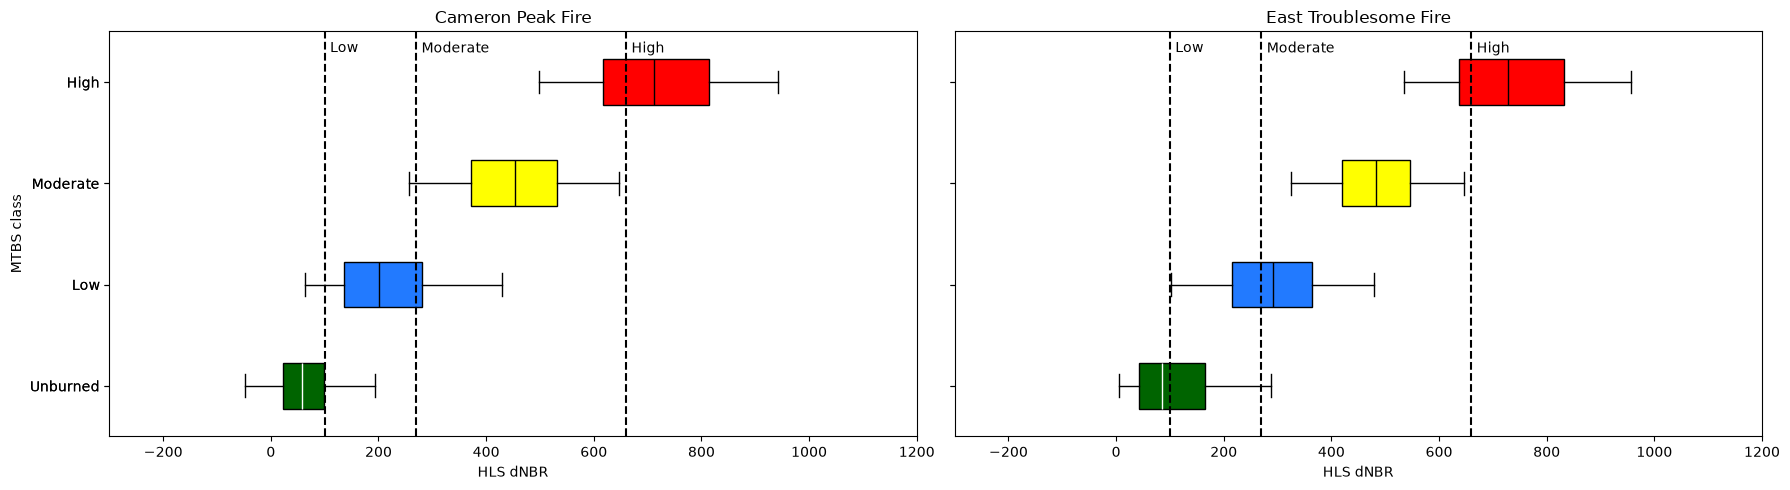

In [11]:
### Key and Benson dNBR value where Low, Moderate, and High start
kb_lines = {"Low": kb_starts["Low"], "Moderate": kb_starts["Moderate-low"], "High": kb_starts["High"]}

### plot the dNBR values in each MTBS class, with the Key and Benson thresholds
fig, axes = plt.subplots(1, 2, figsize=(18, 5), sharey=True)

for ax, fire in zip(axes, fire_keys):
    fire_mtbs = mtbs_shared[fire][compare_masks[fire]]
    fire_dnbr = dnbr_values[fire][compare_masks[fire]]

    ### box plot of each MTBS class (whiskers at the 5th and 95th percentiles)
    boxes = ax.boxplot(
        [fire_dnbr[fire_mtbs == number] for number in range(1, len(shared_names) + 1)],
        orientation="horizontal", whis=(5, 95), showfliers=False, patch_artist=True,
        tick_labels=shared_names, medianprops={"color": "black"}
    )
    for box, color in zip(boxes["boxes"], shared_colors):
        box.set_facecolor(color)

    ### white median line on the dark green box so it shows up
    boxes["medians"][0].set_color("white")

    ### add a line where each Key and Benson class starts, labeled at the top
    for name, start in kb_lines.items():
        ax.axvline(start, color="black", linestyle="--", linewidth=1.5)
        ax.text(start + 10, len(shared_names) + 0.4, name, fontsize=10, va="top")

    ax.set_xlim(-300, 1200)
    ax.set_ylim(0.5, len(shared_names) + 0.5)
    ax.set_title(fire.replace("_", " ").title() + " Fire")
    ax.set_xlabel("HLS dNBR")

axes[0].set_ylabel("MTBS class")

plt.tight_layout()
plt.show()

Figure 1: HLS dNBR values in each MTBS class inside each perimeter, with a dashed line where the Key and Benson Low, Moderate, and High classes start. Boxes show the middle half of the values, and the whiskers reach the 5th and 95th percentiles.

# 3. Compare the Maps

### Where Key and Benson method is higher or lower than MTBS
The maps below show the MTBS classes, the Key and Benson classes, and the Key and Benson class minus the MTBS class. Red pixels are where Key and Benson rates burn severity higher than MTBS, and blue pixels are where it rates it lower.

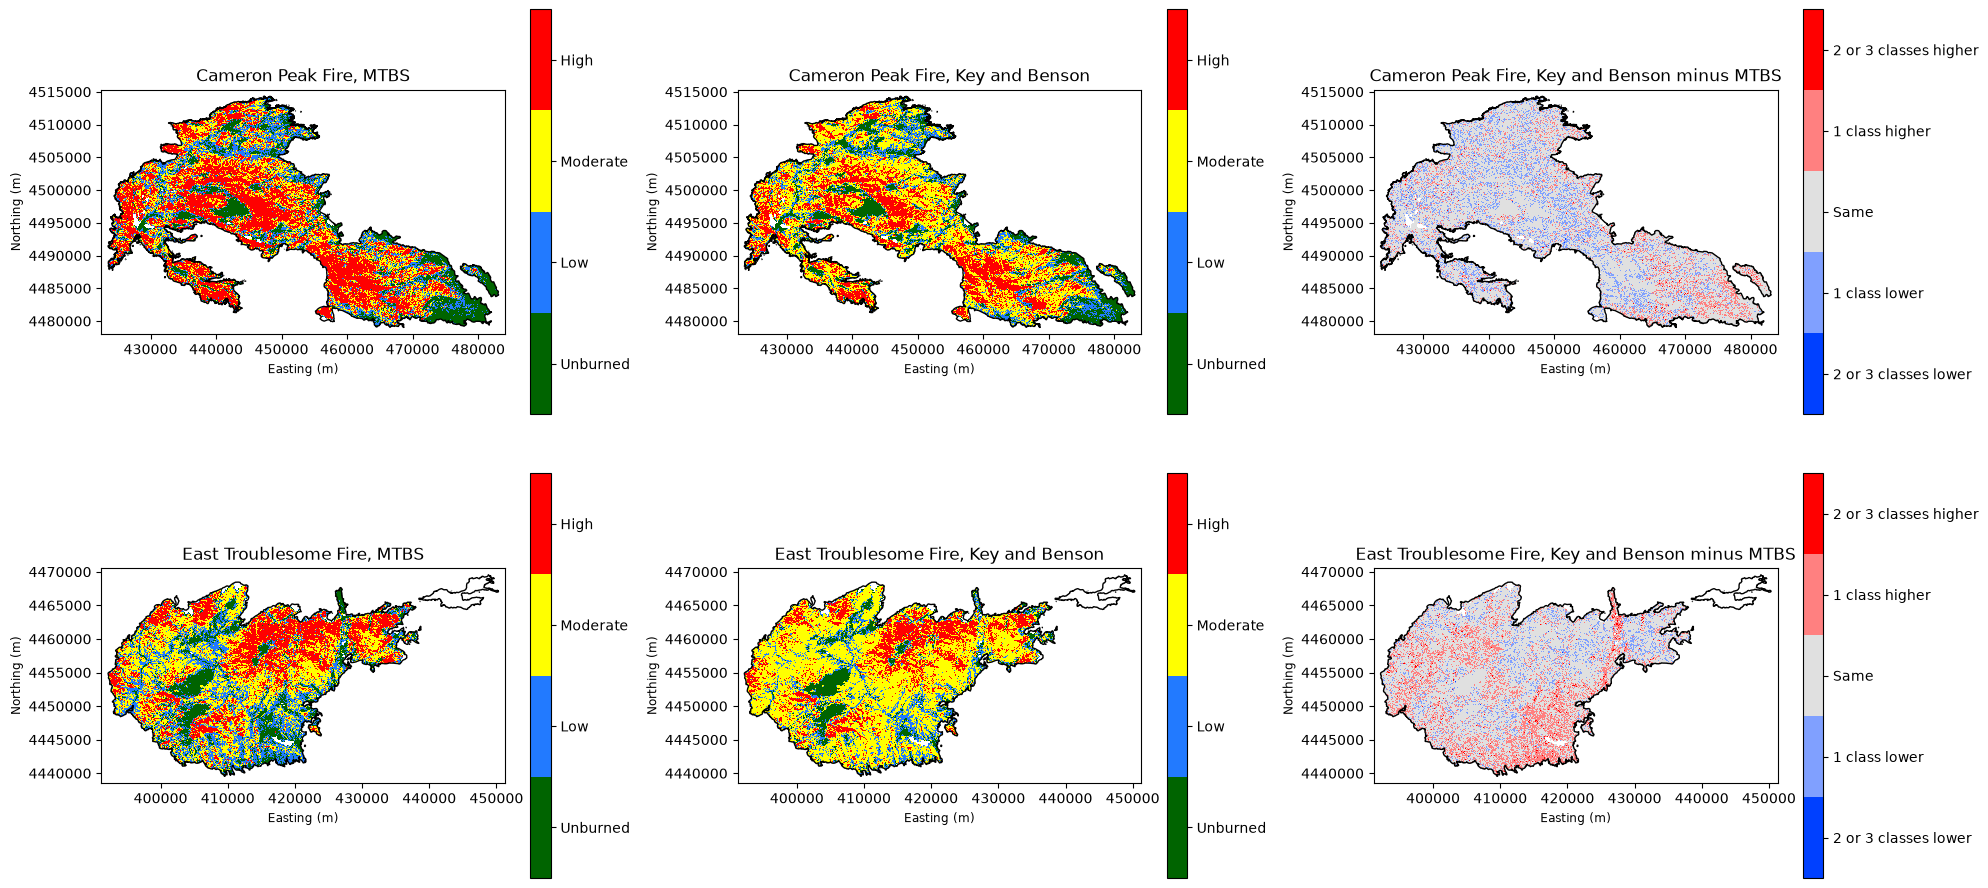

In [12]:
### the Key and Benson class minus the MTBS class, with 2 or more classes apart shown together
difference_names = ["2 or 3 classes lower", "1 class lower", "Same", "1 class higher", "2 or 3 classes higher"]
difference_colors = ["#0040ff", "#80a0ff", "#e0e0e0", "#ff8080", "#ff0000"]

### plot the MTBS map, the Key and Benson map, and the difference for each fire
fig, axes = plt.subplots(2, 3, figsize=(20, 10))

for row, fire in enumerate(fire_keys):
    mask = compare_masks[fire]

    ### MTBS and Key and Benson shared classes, for the compared pixels only
    for ax, classes, title in [(axes[row, 0], mtbs_shared[fire], "MTBS"), (axes[row, 1], kb_shared[fire], "Key and Benson")]:
        class_map = np.where(mask, classes, np.nan)
        class_plot = ax.imshow(class_map, cmap=ListedColormap(shared_colors), vmin=0.5, vmax=len(shared_names) + 0.5,
                               extent=extents[fire], interpolation="nearest")
        colorbar = fig.colorbar(class_plot, ax=ax, ticks=range(1, len(shared_names) + 1), shrink=0.8)
        colorbar.set_ticklabels(shared_names)
        ax.set_title(fire.replace("_", " ").title() + " Fire, " + title)

    ### Key and Benson minus MTBS, for the compared pixels only
    difference = np.where(mask, np.clip(kb_shared[fire] - mtbs_shared[fire], -2, 2), np.nan)
    difference_plot = axes[row, 2].imshow(difference, cmap=ListedColormap(difference_colors), vmin=-2.5, vmax=2.5,
                                          extent=extents[fire], interpolation="nearest")
    colorbar = fig.colorbar(difference_plot, ax=axes[row, 2], ticks=range(-2, 3), shrink=0.8)
    colorbar.set_ticklabels(difference_names)
    axes[row, 2].set_title(fire.replace("_", " ").title() + " Fire, Key and Benson minus MTBS")

    ### add the fire perimeter, and zoom to it (only the pixels inside it are compared)
    perimeter = perimeters_utm[perimeters_utm["fire"] == fire]
    minx, miny, maxx, maxy = perimeter.total_bounds

    for ax in axes[row]:
        perimeter.boundary.plot(ax=ax, color="black", linewidth=1)
        ax.set_xlim(minx - 1000, maxx + 1000)
        ax.set_ylim(miny - 1000, maxy + 1000)
        ax.ticklabel_format(style="plain")
        ax.set_xlabel("Easting (m)")
        ax.set_ylabel("Northing (m)")

plt.tight_layout()
plt.show()

Figure 2: The MTBS classes (left), the Key and Benson classes (middle), and the Key and Benson class minus the MTBS class (right), for the Cameron Peak Fire (top) and the East Troublesome Fire (bottom). Only the compared pixels are shown, with the NIFC perimeter in black.

### Area in each class
Areas are counted over the compared pixels only, so both maps cover the same area.

In [13]:
### area of each shared class in the compared pixels, for both maps
area_rows = []

for fire in fire_keys:
    for map_name, classes in [("MTBS", mtbs_shared[fire]), ("Key and Benson", kb_shared[fire])]:
        values = classes[compare_masks[fire]]

        for number, name in enumerate(shared_names, start=1):
            pixels = (values == number).sum()
            area_rows.append({
                "fire": fire,
                "map": map_name,
                "class": name,
                "acres": pixels * cell_size**2 / m2_per_acre,
                "percent": pixels / len(values) * 100,
            })

area_df = pd.DataFrame(area_rows)

### acres and percent of each fire in each class
area_df.pivot_table(index=["fire", "map"], columns="class", values=["acres", "percent"], sort=False).round(1)

acres                              percent  \
class                           Unburned      Low  Moderate     High Unburned   
fire             map                                                            
cameron_peak     MTBS            38062.9  41683.7   47371.9  79675.2     18.4   
                 Key and Benson  34189.0  36368.0   83328.9  52907.7     16.5   
east_troublesome MTBS            28644.5  46423.8   63669.9  46859.0     15.4   
                 Key and Benson  18200.1  29246.5  103253.9  34896.6      9.8   

                                                      
class                             Low Moderate  High  
fire             map                                  
cameron_peak     MTBS            20.2     22.9  38.5  
                 Key and Benson  17.6     40.3  25.6  
east_troublesome MTBS            25.0     34.3  25.2  
                 Key and Benson  15.8     55.6  18.8

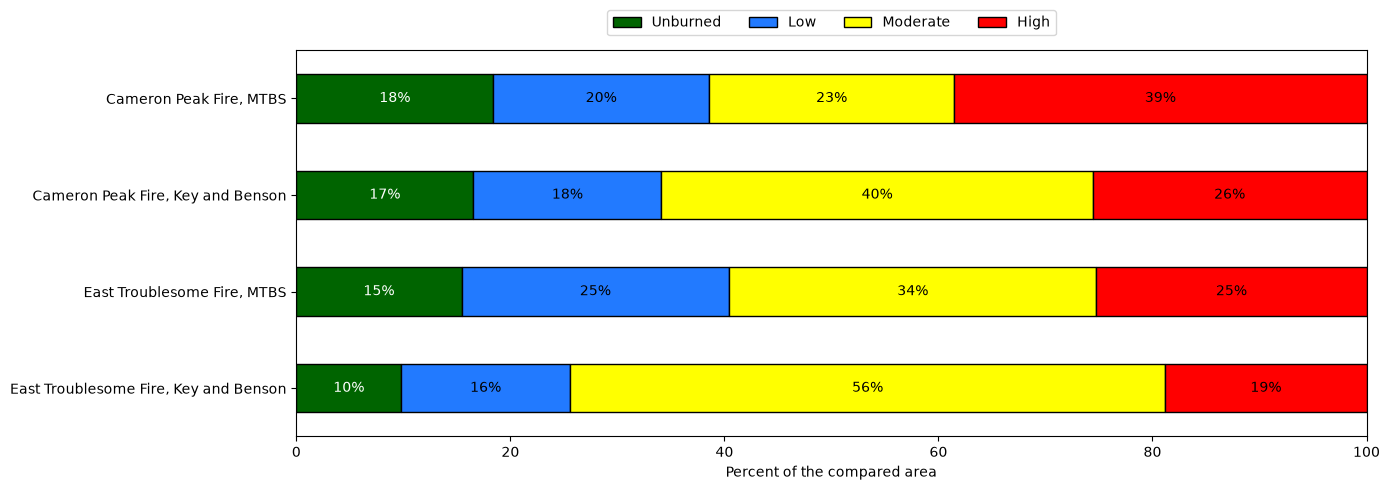

In [14]:
### percent of each fire in each shared class, for both maps
percent_df = area_df.pivot_table(index=["fire", "map"], columns="class", values="percent", sort=False)[shared_names]
percent_df.index = [fire.replace("_", " ").title() + " Fire, " + map_name for fire, map_name in percent_df.index]

### stacked bar of the classes for each fire and map
fig, ax = plt.subplots(figsize=(14, 5))
percent_df.plot(kind="barh", stacked=True, color=shared_colors, edgecolor="black", ax=ax)

### write the percent in the classes wide enough to fit it
for bars, name in zip(ax.containers, shared_names):
    labels = [str(round(width)) + "%" if width >= 4 else "" for width in bars.datavalues]
    ax.bar_label(bars, labels=labels, label_type="center", color="white" if name == "Unburned" else "black")

### Cameron Peak on top
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Percent of the compared area")
ax.legend(title="", ncol=4, loc="lower center", bbox_to_anchor=(0.5, 1.02))

plt.tight_layout()
plt.show()

Figure 3: Percent of the compared area in each shared class, for the MTBS map and the Key and Benson map of each fire.

### Agreement with MTBS
The two maps are compared pixel by pixel:
- **agreement:** percent of the pixels in the same shared class in both maps
- **kappa:** Cohen's kappa, the agreement after taking out the agreement two maps would have by chance. 0 is no better than chance and 1 is perfect. 0.4 to 0.6 is often called moderate agreement, and above 0.6 substantial agreement (Landis and Koch, 1977)
- **higher** and **lower:** percent of the pixels Key and Benson rates more or less severe than MTBS
- **mtbs_high** and **kb_high:** percent of the pixels that MTBS and Key and Benson call High
- **mtbs_high_also_kb_high:** percent of the MTBS High pixels that Key and Benson also calls High
- **kb_high_also_mtbs_high:** percent of the Key and Benson High pixels that MTBS also calls High

In [15]:
### create a function to compare the Key and Benson shared classes with the MTBS shared classes
def compare_to_mtbs(mtbs_classes, kb_classes):
    """
    Compare the Key and Benson shared classes with the MTBS shared classes, pixel by pixel

    Args:
    mtbs_classes (numpy.ndarray): MTBS shared class numbers (1-4) for the compared pixels
    kb_classes (numpy.ndarray): Key and Benson shared class numbers (1-4) for the same pixels

    Returns:
    dict: agreement numbers, and the pixel count for each pair of classes (rows are MTBS, columns are Key and Benson)
    """

    ### count the pixels for each pair of classes: rows are MTBS, columns are Key and Benson
    n = len(shared_names)
    counts = np.zeros((n, n), dtype=int)
    for i in range(n):
        for j in range(n):
            counts[i, j] = ((mtbs_classes == i + 1) & (kb_classes == j + 1)).sum()
    shares = counts / counts.sum()

    ### agreement, and the agreement expected by chance from how much of each class the two maps have
    agreement = np.trace(shares)
    chance = (shares.sum(axis=1) * shares.sum(axis=0)).sum()

    return {
        "agreement": agreement * 100,
        "kappa": (agreement - chance) / (1 - chance),
        "higher": np.triu(shares, k=1).sum() * 100,
        "lower": np.tril(shares, k=-1).sum() * 100,
        "mtbs_high": shares[-1].sum() * 100,
        "kb_high": shares[:, -1].sum() * 100,
        "mtbs_high_also_kb_high": counts[-1, -1] / counts[-1].sum() * 100,
        "kb_high_also_mtbs_high": counts[-1, -1] / counts[:, -1].sum() * 100,
        "counts": counts,
    }

In [16]:
### compare the two maps for both fires
agreement_rows = []
pixel_counts = {}

for fire in fire_keys:
    mask = compare_masks[fire]
    result = compare_to_mtbs(mtbs_shared[fire][mask], kb_shared[fire][mask])
    pixel_counts[fire] = result.pop("counts")
    row = {"fire": fire}
    row.update(result)
    agreement_rows.append(row)

agreement_df = pd.DataFrame(agreement_rows)

### check it
agreement_df.round(2)

,fire,agreement,kappa,higher,lower,mtbs_high,kb_high,mtbs_high_also_kb_high,kb_high_also_mtbs_high
0,cameron_peak,70.89,0.61,11.10,18.01,38.53,25.58,63.94,96.29
1,east_troublesome,67.69,0.54,22.65,9.66,25.25,18.80,68.80,92.38


### Class by class
Each table shows where the pixels in each MTBS class end up in the Key and Benson map. Rows are the MTBS classes and add up to 100%.

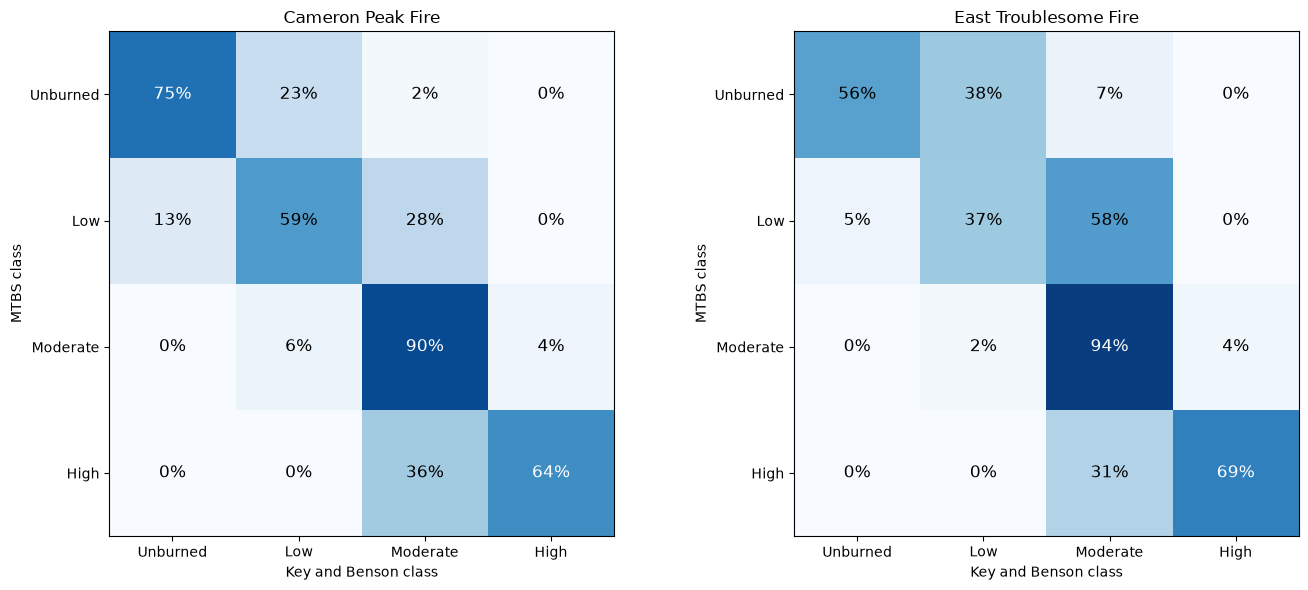

In [17]:
### percent of each MTBS class in each Key and Benson class
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, fire in zip(axes, fire_keys):
    counts = pixel_counts[fire]
    row_percent = counts / counts.sum(axis=1, keepdims=True) * 100

    ax.imshow(row_percent, cmap="Blues", vmin=0, vmax=100)

    ### write the percent in each cell
    for i in range(len(shared_names)):
        for j in range(len(shared_names)):
            text_color = "white" if row_percent[i, j] > 60 else "black"
            ax.text(j, i, str(round(row_percent[i, j])) + "%", ha="center", va="center", color=text_color, fontsize=12)

    ax.set_xticks(range(len(shared_names)), shared_names)
    ax.set_yticks(range(len(shared_names)), shared_names)
    ax.set_xlabel("Key and Benson class")
    ax.set_ylabel("MTBS class")
    ax.set_title(fire.replace("_", " ").title() + " Fire")

plt.tight_layout()
plt.show()

Figure 4: Percent of each MTBS class (rows) in each Key and Benson class (columns). The diagonal is where the two maps agree.

# 4. Save the Results
Two tables are saved to data/comparison: the agreement numbers for each fire, and the pixels and acres for each pair of MTBS and Key and Benson classes.

In [18]:
### save the agreement table
agreement_path = os.path.join(comparison_dir, "mtbs_agreement.csv")
agreement_df.to_csv(agreement_path, index=False)

### make a table of the pixels and acres for each pair of MTBS and Key and Benson classes
pair_rows = []

for fire, counts in pixel_counts.items():
    for i, mtbs_class in enumerate(shared_names):
        for j, kb_class in enumerate(shared_names):
            pair_rows.append({
                "fire": fire,
                "mtbs_class": mtbs_class,
                "kb_class": kb_class,
                "pixels": counts[i, j],
                "acres": counts[i, j] * cell_size**2 / m2_per_acre,
                "percent_of_mtbs_class": counts[i, j] / counts[i].sum() * 100,
            })

pairs_path = os.path.join(comparison_dir, "mtbs_class_pairs.csv")
pd.DataFrame(pair_rows).to_csv(pairs_path, index=False)

print("Saved agreement table to:", agreement_path)
print("Saved class pairs table to:", pairs_path)

Saved agreement table to: C:\Users\warno\Documents\GitHub\Fire_Burn_Severity\data\comparison\mtbs_agreement.csv
Saved class pairs table to: C:\Users\warno\Documents\GitHub\Fire_Burn_Severity\data\comparison\mtbs_class_pairs.csv


# 5. Summary
The Key and Benson map agrees with MTBS on about 70% of the compared area (71% at Cameron Peak and 68% at East Troublesome). The kappas are 0.61 and 0.54, which is substantial and moderate agreement.

- The "Moderate" class matches best in the comparison. 90% of the MTBS Moderate area at Cameron Peak and 94% at East Troublesome is also Moderate in the Key and Benson map
- Key and Benson maps less high severity than MTBS: 26% of Cameron Peak compared to 39% in MTBS, and 19% of East Troublesome compared to 25%. About a third of the MTBS High area is Moderate in the Key and Benson map (Figure 4), because its HLS dNBR is below the Key and Benson High threshold of 660 (Figure 1). The MTBS analysts started High lower for these fires, at 490 and 540
- At East Troublesome, Key and Benson rates much of the MTBS Unburned and Low area one class higher (Figure 2). The Key and Benson map also has low pixels outside the East Troublesome perimeter (Figure 3 in 02_burn_severity), so part of this is likely a small rise in dNBR from 2019 to 2021 that isn't from the fire.

For the watershed and WUI analysis, this means the high severity areas from the Key and Benson map are on the low side compared with MTBS.


# Citations
- Cohen, J. (1960). A coefficient of agreement for nominal scales. *Educational and Psychological Measurement, 20*(1), 37-46. https://doi.org/10.1177/001316446002000104
- Congalton, R. G. (1991). A review of assessing the accuracy of classifications of remotely sensed data. *Remote Sensing of Environment, 37*(1), 35-46. https://doi.org/10.1016/0034-4257(91)90048-B
- Eidenshink, J., Schwind, B., Brewer, K., Zhu, Z.-L., Quayle, B., & Howard, S. (2007). A project for monitoring trends in burn severity. *Fire Ecology, 3*(1), 3-21. https://doi.org/10.4996/fireecology.0301003
- Key, C. H., & Benson, N. C. (2006). Landscape assessment (LA): Sampling and analysis methods. In D. C. Lutes et al. (Eds.), *FIREMON: Fire effects monitoring and inventory system* (Gen. Tech. Rep. RMRS-GTR-164-CD, pp. LA-1-LA-55). USDA Forest Service, Rocky Mountain Research Station.
- Kolden, C. A., Smith, A. M. S., & Abatzoglou, J. T. (2015). Limitations and utilisation of Monitoring Trends in Burn Severity products for assessing wildfire severity in the USA. *International Journal of Wildland Fire, 24*(7), 1023-1028. https://doi.org/10.1071/WF15082
- Landis, J. R., & Koch, G. G. (1977). The measurement of observer agreement for categorical data. *Biometrics, 33*(1), 159-174. https://doi.org/10.2307/2529310